# 08. Xử lý mất cân bằng khi huấn luyện và chọn mô hình cuối
Notebook 04 đã xử lý mất cân bằng ở khâu dữ liệu (biến đổi log, chia tập phân tầng, tính trọng số, tạo tập tăng mẫu). Ở đây so sánh **5 cách huấn luyện** trên cùng mô hình LightGBM (cấu hình đã dò ở notebook 07), đánh giá **theo từng nhóm** trên tập test:

| Cách | Mô tả |
|---|---|
| 1. Không xử lý | Mỗi mẫu có trọng số như nhau |
| 2. Trọng số tầng (căn bậc hai) | $w = (1/p_{tầng})^{0.5}$ – tầng = loại BĐS × vùng × phân khúc giá |
| 3. Trọng số tầng (đầy đủ) | $w = 1/p_{tầng}$ – cân bằng mạnh |
| 4. Trọng số theo phân khúc giá | Chỉ cân bằng theo phân khúc giá (nhắm vào nhà rất rẻ / rất đắt) |
| 5. Tăng mẫu nhóm hiếm | Nhân bản tầng < 2.000 mẫu lên 2.000 mẫu, có nhiễu nhỏ |

Sau đó chọn mô hình cuối dựa trên tập validation (độ chính xác chung **và** độ công bằng giữa các nhóm), phân tích sai số trên tập test và mức độ quan trọng của đặc trưng.

In [1]:
import sys, os, time, json, warnings
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from danh_gia import chi_so, theo_nhom, THU_TU_PHAN_KHUC
from can_bang import trong_so_nghich_tan_suat

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
sns.set_theme(style='whitegrid')
FIG = '../reports/figures'
doc = lambda t: pd.read_parquet(f'../data/processed/dac_trung_{t}.parquet')
tr, va, te, tm = doc('train'), doc('val'), doc('test'), doc('train_tang_mau')
ens = json.load(open('../models/ensemble.json', encoding='utf-8'))
COT_X, TS_LGB = ens['dac_trung'], ens['tham_so_lgb']
X_tr, y_tr = tr[COT_X].values, tr['y'].values.astype(np.float64)
X_va, y_va = va[COT_X].values, va['y'].values.astype(np.float64)
X_te, y_te = te[COT_X].values, te['y'].values.astype(np.float64)
tang_tr = tr['_loai_bds'] + ' | ' + tr['_vung'] + ' | ' + tr['_phan_khuc']
TRONG_SO = {
    'Không xử lý': np.ones(len(tr)),
    'Trọng số tầng (căn bậc hai)': tr['trong_so'].values.astype(np.float64),
    'Trọng số tầng (đầy đủ)': trong_so_nghich_tan_suat(tang_tr, mu=1.0, thap=0.05, cao=20).values,
    'Trọng số theo phân khúc giá': trong_so_nghich_tan_suat(tr['_phan_khuc'], mu=1.0, thap=0.05, cao=20).values,
}
print('Trọng số lớn nhất / nhỏ nhất:', {k: (round(float(v.max()), 2), round(float(v.min()), 3)) for k, v in TRONG_SO.items()})

Trọng số lớn nhất / nhỏ nhất: {'Không xử lý': (1.0, 1.0), 'Trọng số tầng (căn bậc hai)': (5.08, 0.41), 'Trọng số tầng (đầy đủ)': (23.9, 0.106), 'Trọng số theo phân khúc giá': (3.49, 0.592)}


## 1. Huấn luyện 5 biến thể

In [2]:
def lgb_mh(n):
    return lgb.LGBMRegressor(n_estimators=n, learning_rate=0.05, subsample_freq=1, n_jobs=-1, random_state=42, verbose=-1, **TS_LGB)
goc = lgb_mh(20000).fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(200, verbose=False)])
SO_CAY = goc.best_iteration_
print('Số cây (dừng sớm theo validation):', SO_CAY)
bien_the = {'Không xử lý': goc}
for ten in list(TRONG_SO)[1:]:
    t = time.time()
    bien_the[ten] = lgb_mh(SO_CAY).fit(X_tr, y_tr, sample_weight=TRONG_SO[ten])
    print(f'{ten}: {time.time() - t:.0f}s')
t = time.time()
bien_the['Tăng mẫu nhóm hiếm'] = lgb_mh(SO_CAY).fit(tm[COT_X].values, tm['y'].values)
print(f'Tăng mẫu nhóm hiếm: {time.time() - t:.0f}s')

Số cây (dừng sớm theo validation): 2738


Trọng số tầng (căn bậc hai): 237s


Trọng số tầng (đầy đủ): 232s


Trọng số theo phân khúc giá: 215s


Tăng mẫu nhóm hiếm: 257s


In [3]:
CHIEU = [('_loai_bds', 'loại BĐS'), ('_vung', 'vùng'), ('_phan_khuc', 'phân khúc giá')]
tong, chi_tiet, du_doan = {}, [], {}
for ten, mh in bien_the.items():
    p = mh.predict(X_te)
    du_doan[ten] = p
    h = chi_so(y_te, p)
    for cot, nhan in CHIEU:
        g = theo_nhom(y_te, p, te[cot])
        h[f'MAPE macro – {nhan}'] = g['MAPE'].mean()
        h[f'MAPE nhóm tệ nhất – {nhan}'] = g['MAPE'].max()
        chi_tiet.append(g.reset_index().assign(cach=ten, chieu=nhan))
    tong[ten] = h
tong = pd.DataFrame(tong).T
chi_tiet = pd.concat(chi_tiet, ignore_index=True)
chi_tiet.to_csv('../reports/mat_can_bang_theo_nhom.csv', index=False, encoding='utf-8-sig')
tong.to_csv('../reports/mat_can_bang_tong_hop.csv', encoding='utf-8-sig')
tong[['RMSE log', 'MAPE (%)', 'Lệch ≤20% (%)', 'MAPE macro – loại BĐS', 'MAPE nhóm tệ nhất – loại BĐS', 'MAPE macro – vùng',
      'MAPE macro – phân khúc giá', 'MAPE nhóm tệ nhất – phân khúc giá']].style.format('{:.3f}').background_gradient(cmap='RdYlGn_r', axis=0)

,RMSE log,MAPE (%),Lệch ≤20% (%),MAPE macro – loại BĐS,MAPE nhóm tệ nhất – loại BĐS,MAPE macro – vùng,MAPE macro – phân khúc giá,MAPE nhóm tệ nhất – phân khúc giá
Không xử lý,0.379,27.903,56.960,25.077,44.027,28.916,36.015,90.151
Trọng số tầng (căn bậc hai),0.382,28.408,56.440,25.348,45.371,29.435,36.619,93.442
Trọng số tầng (đầy đủ),0.388,29.190,55.090,25.920,46.552,30.188,37.290,95.021
Trọng số theo phân khúc giá,0.383,27.991,56.296,25.334,43.200,28.904,34.577,80.338
Tăng mẫu nhóm hiếm,0.377,27.767,57.876,24.940,44.749,28.883,36.029,91.249


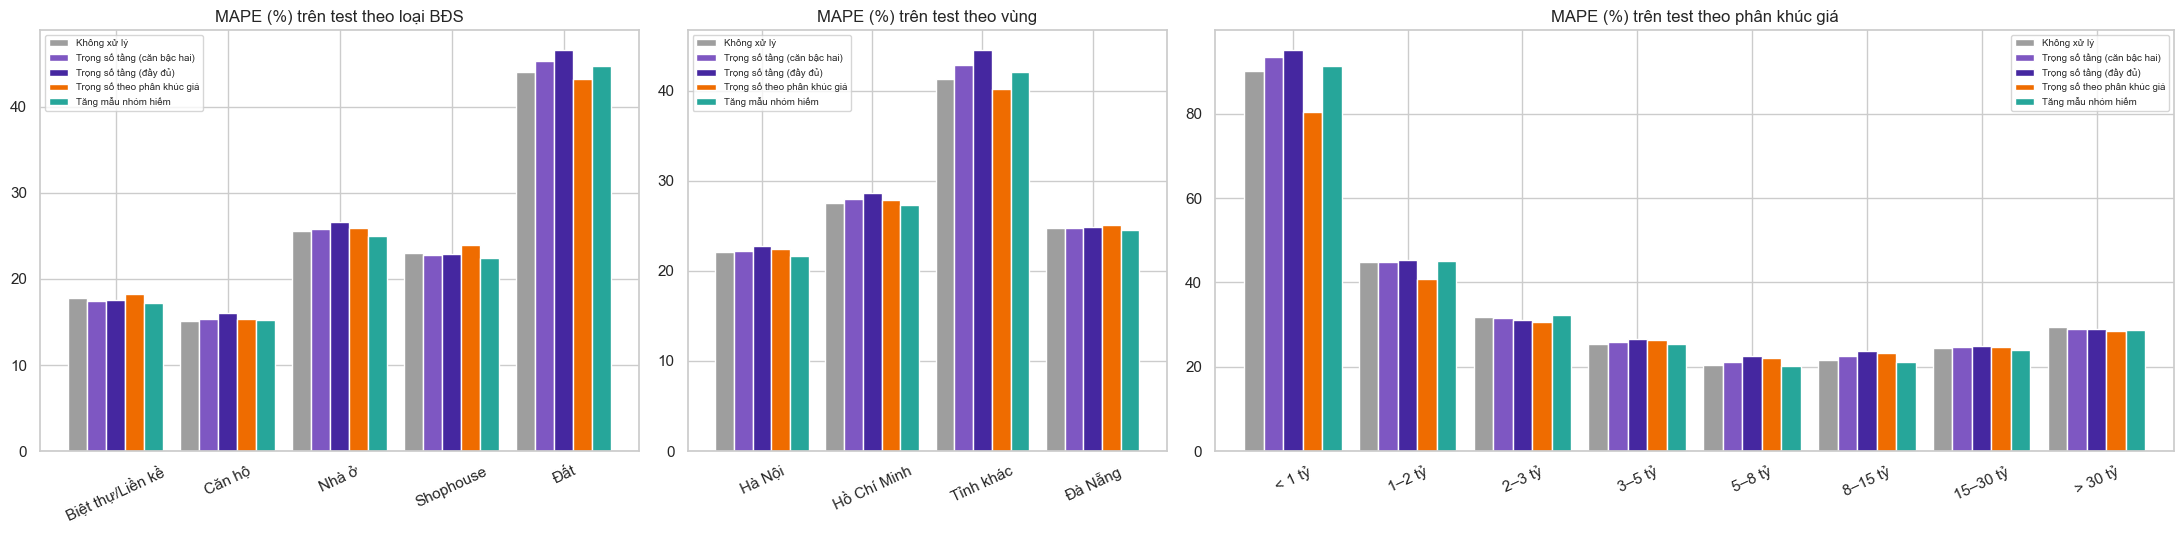

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(22, 5.5), gridspec_kw={'width_ratios': [5, 4, 8]})
mau = ['#9e9e9e', '#7e57c2', '#4527a0', '#ef6c00', '#26a69a']
for a, (cot, nhan) in zip(ax, CHIEU):
    d = chi_tiet[chi_tiet['chieu'] == nhan].pivot(index='nhom', columns='cach', values='MAPE')[list(bien_the)]
    if nhan == 'phân khúc giá':
        d = d.loc[[k for k in THU_TU_PHAN_KHUC if k in d.index]]
    d.plot(kind='bar', ax=a, rot=25, color=mau, width=0.85)
    a.set_title(f'MAPE (%) trên test theo {nhan}'); a.set_xlabel(''); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{FIG}/08_mat_can_bang.png', dpi=120); plt.show()

In [5]:
thay_doi = chi_tiet.pivot_table(index=['chieu', 'nhom'], columns='cach', values='MAPE')
for ten in list(bien_the)[1:]:
    thay_doi[f'Δ {ten}'] = thay_doi[ten] - thay_doi['Không xử lý']
so_mau = chi_tiet[chi_tiet['cach'] == 'Không xử lý'].set_index(['chieu', 'nhom'])['so_mau']
thay_doi.insert(0, 'Số mẫu test', so_mau)
thay_doi[['Số mẫu test', 'Không xử lý'] + [c for c in thay_doi.columns if c.startswith('Δ')]].round(2).style.format(precision=2).background_gradient(
    subset=[c for c in thay_doi.columns if c.startswith('Δ')], cmap='RdYlGn_r', vmin=-3, vmax=3)

## 2. Chọn mô hình cuối
Ứng viên: các biến thể LightGBM ở trên và các mô hình/ensemble tốt nhất ở notebook 07. Xếp hạng trên **tập validation** theo 2 tiêu chí: RMSE chung và MAPE trung bình giữa các loại BĐS (công bằng với nhóm hiếm). Tổng hạng nhỏ nhất được chọn.

In [6]:
dv07, dt07 = pd.read_parquet('../data/processed/du_doan_val.parquet'), pd.read_parquet('../data/processed/du_doan_test.parquet')
ung_vien_val = {f'LightGBM – {k}': mh.predict(X_va) for k, mh in bien_the.items()}
ung_vien_test = {f'LightGBM – {k}': du_doan[k] for k in bien_the}
for k in [c for c in dv07.columns if c.startswith(('Ensemble', 'XGBoost', 'CatBoost'))]:
    ung_vien_val[k], ung_vien_test[k] = dv07[k].values.astype(np.float64), dt07[k].values.astype(np.float64)
bang_chon = pd.DataFrame({k: {'RMSE val': chi_so(y_va, p)['RMSE log'],
                              'MAPE macro loại BĐS (val)': theo_nhom(y_va, p, va['_loai_bds'])['MAPE'].mean(),
                              'MAPE macro phân khúc (val)': theo_nhom(y_va, p, va['_phan_khuc'])['MAPE'].mean()} for k, p in ung_vien_val.items()}).T
bang_chon['Tổng hạng'] = bang_chon.rank().sum(axis=1)
bang_chon = bang_chon.sort_values(['Tổng hạng', 'RMSE val'])
TEN_CUOI = bang_chon.index[0]
print('MÔ HÌNH CUỐI:', TEN_CUOI)
bang_chon.round(4)

MÔ HÌNH CUỐI: Ensemble: trọng số tối ưu (NNLS)


,RMSE val,MAPE macro loại BĐS (val),MAPE macro phân khúc (val),Tổng hạng
Ensemble: trọng số tối ưu (NNLS),0.3793,25.1933,36.4908,4.0
Ensemble: trung bình 3 boosting,0.3806,25.4377,36.7846,9.0
LightGBM – Không xử lý,0.3826,25.3711,36.6216,9.0
LightGBM – Tăng mẫu nhóm hiếm,0.3813,25.5060,36.8098,12.0
LightGBM – Trọng số theo phân khúc giá,0.3870,25.5939,35.0953,13.0
LightGBM – Trọng số tầng (căn bậc hai),0.3852,25.7324,37.1503,17.0
XGBoost (3867 cây),0.3866,26.1141,37.8335,20.0
LightGBM – Trọng số tầng (đầy đủ),0.3910,26.2993,37.9610,25.0
CatBoost (6000 cây),0.3898,26.6127,38.0419,26.0


In [7]:
p_te = ung_vien_test[TEN_CUOI]
kq_test = chi_so(y_te, p_te)
pd.Series(kq_test, name=f'{TEN_CUOI} – tập TEST').round(4).to_frame()

,Ensemble: trọng số tối ưu (NNLS) – tập TEST
RMSE log,0.3758
R² log,0.8807
MAE (tỷ),3.8660
MAPE (%),27.7887
Trung vị APE (%),16.5450
Lệch ≤10% (%),33.4651
Lệch ≤20% (%),57.1725


## 3. Phân tích sai số của mô hình cuối trên tập test

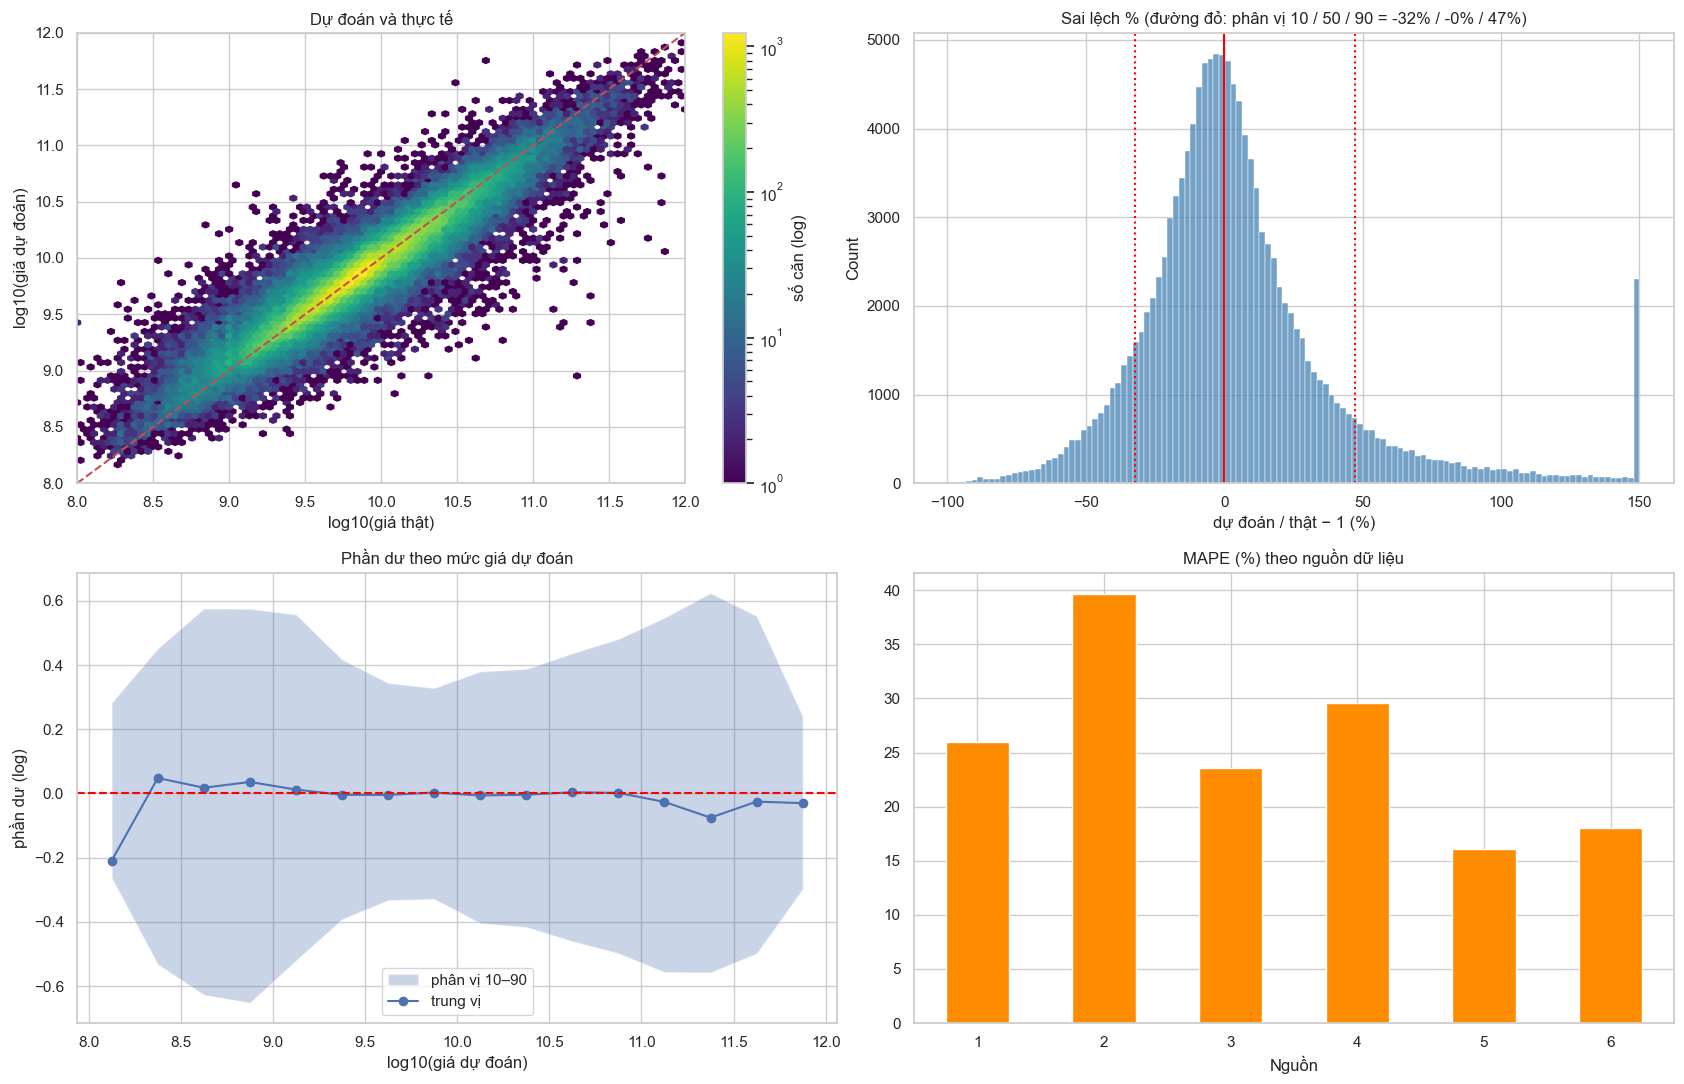

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(17, 11))
hb = ax[0, 0].hexbin(y_te / np.log(10), p_te / np.log(10), gridsize=90, bins='log', cmap='viridis', mincnt=1)
ax[0, 0].plot([8, 12], [8, 12], 'r--'); ax[0, 0].set_xlim(8, 12); ax[0, 0].set_ylim(8, 12)
ax[0, 0].set_xlabel('log10(giá thật)'); ax[0, 0].set_ylabel('log10(giá dự đoán)'); ax[0, 0].set_title('Dự đoán và thực tế')
fig.colorbar(hb, ax=ax[0, 0], label='số căn (log)')
sai = (np.exp(p_te - y_te) - 1) * 100
sns.histplot(np.clip(sai, -100, 150), bins=120, ax=ax[0, 1], color='steelblue')
for q, ls in [(10, ':'), (50, '-'), (90, ':')]:
    ax[0, 1].axvline(np.percentile(sai, q), color='red', ls=ls)
ax[0, 1].set_title(f'Sai lệch % (đường đỏ: phân vị 10 / 50 / 90 = {np.percentile(sai, 10):.0f}% / {np.percentile(sai, 50):.0f}% / {np.percentile(sai, 90):.0f}%)')
ax[0, 1].set_xlabel('dự đoán / thật − 1 (%)')
du = pd.DataFrame({'du_doan': p_te / np.log(10), 'phan_du': p_te - y_te})
du['khoang'] = pd.cut(du['du_doan'], np.arange(8, 12.01, 0.25))
g = du.groupby('khoang', observed=True)['phan_du'].describe(percentiles=[0.1, 0.5, 0.9])
x = [i.mid for i in g.index]
ax[1, 0].fill_between(x, g['10%'], g['90%'], alpha=0.3, label='phân vị 10–90')
ax[1, 0].plot(x, g['50%'], marker='o', label='trung vị'); ax[1, 0].axhline(0, color='red', ls='--')
ax[1, 0].set_xlabel('log10(giá dự đoán)'); ax[1, 0].set_ylabel('phần dư (log)'); ax[1, 0].set_title('Phần dư theo mức giá dự đoán'); ax[1, 0].legend()
nguon = theo_nhom(y_te, p_te, te['_nguon'])
nguon['MAPE'].plot(kind='bar', ax=ax[1, 1], color='darkorange', rot=0)
ax[1, 1].set_title('MAPE (%) theo nguồn dữ liệu'); ax[1, 1].set_xlabel('Nguồn')
plt.tight_layout(); plt.savefig(f'{FIG}/08_phan_tich_sai_so.png', dpi=120); plt.show()

## 4. Mức độ quan trọng của đặc trưng – permutation importance
Xáo trộn ngẫu nhiên từng đặc trưng trên 20.000 mẫu test rồi đo RMSE tăng bao nhiêu: tăng càng nhiều thì mô hình càng phụ thuộc vào đặc trưng đó. Cách này áp dụng được cho mọi mô hình (kể cả ensemble).

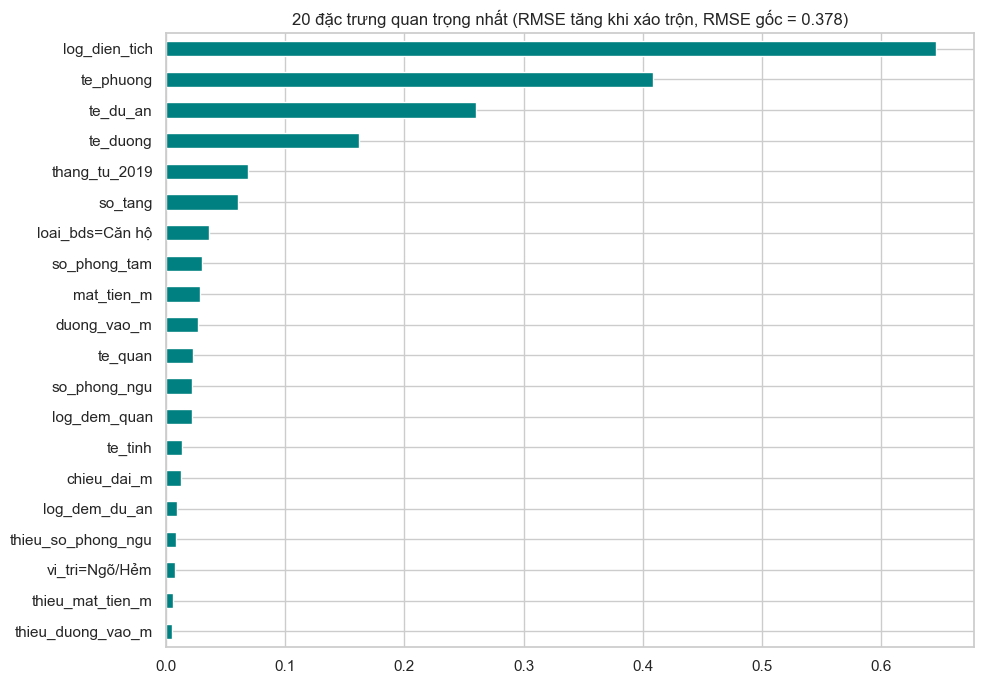

In [9]:
mh_xgb = xgb.XGBRegressor(); mh_xgb.load_model('../models/xgb.json')
mh_lgb = lgb.Booster(model_file='../models/lightgbm.txt')
mh_cat = CatBoostRegressor(); mh_cat.load_model('../models/catboost.cbm')
def du_doan_cuoi(X):
    if TEN_CUOI.startswith('LightGBM – '):
        return bien_the[TEN_CUOI.replace('LightGBM – ', '')].predict(X)
    if TEN_CUOI.startswith('Ensemble'):
        w = ens['trong_so'] if 'NNLS' in TEN_CUOI else {k: 1 / 3 for k in ens['thanh_phan']}
        p = {'XGBoost': mh_xgb.predict(X), 'LightGBM': mh_lgb.predict(X), 'CatBoost': mh_cat.predict(X)}
        return sum(w[k] * p[k.split(' ')[0]] for k in ens['thanh_phan'])
    return {'XGBoost': mh_xgb, 'CatBoost': mh_cat}[TEN_CUOI.split(' ')[0]].predict(X)
rng = np.random.default_rng(0)
idx = rng.choice(len(X_te), 20000, replace=False)
Xs, ys = X_te[idx].copy(), y_te[idx]
co_so = chi_so(ys, du_doan_cuoi(Xs))['RMSE log']
pi = {}
for j, ten in enumerate(COT_X):
    luu = Xs[:, j].copy()
    Xs[:, j] = rng.permutation(luu)
    pi[ten] = chi_so(ys, du_doan_cuoi(Xs))['RMSE log'] - co_so
    Xs[:, j] = luu
pi = pd.Series(pi).sort_values()
ax = pi.tail(20).plot(kind='barh', figsize=(10, 7), color='teal')
ax.set_title(f'20 đặc trưng quan trọng nhất (RMSE tăng khi xáo trộn, RMSE gốc = {co_so:.3f})')
plt.tight_layout(); plt.savefig(f'{FIG}/08_permutation_importance.png', dpi=120); plt.show()
pi.to_csv('../reports/permutation_importance.csv', encoding='utf-8-sig')

## 5. Lưu mô hình cuối cho ứng dụng

In [10]:
if TEN_CUOI.startswith('LightGBM – '):
    bien_the[TEN_CUOI.replace('LightGBM – ', '')].booster_.save_model('../models/lightgbm_cuoi.txt')
    cau_hinh = {'loai': 'lightgbm', 'tep': ['lightgbm_cuoi.txt'], 'trong_so': {'lightgbm_cuoi.txt': 1.0}}
elif TEN_CUOI.startswith('Ensemble'):
    w = ens['trong_so'] if 'NNLS' in TEN_CUOI else {k: 1 / 3 for k in ens['thanh_phan']}
    tep = {'XGBoost': 'xgb.json', 'LightGBM': 'lightgbm.txt', 'CatBoost': 'catboost.cbm'}
    cau_hinh = {'loai': 'ensemble', 'tep': [tep[k.split(' ')[0]] for k in ens['thanh_phan']],
                'trong_so': {tep[k.split(' ')[0]]: float(w[k]) for k in ens['thanh_phan']}}
else:
    tep = {'XGBoost': 'xgb.json', 'CatBoost': 'catboost.cbm'}[TEN_CUOI.split(' ')[0]]
    cau_hinh = {'loai': 'don', 'tep': [tep], 'trong_so': {tep: 1.0}}
r = np.exp(p_te - y_te)
khoang = {'Tất cả': [float(1 / np.quantile(r, 0.9)), float(1 / np.quantile(r, 0.1))]}
for loai, i in te.groupby('_loai_bds').indices.items():
    khoang[loai] = [float(1 / np.quantile(r[i], 0.9)), float(1 / np.quantile(r[i], 0.1))]
so_sanh = pd.read_csv('../reports/so_sanh_tat_ca_mo_hinh.csv', index_col=0)
thong_tin = {
    'mo_hinh': TEN_CUOI, **cau_hinh, 'dac_trung': COT_X, 'ket_qua_test': kq_test, 'khoang_sai_so': khoang,
    'so_mau_train': int(len(tr)), 'so_mau_val': int(len(va)), 'so_mau_test': int(len(te)),
    'so_sanh': [{'mo_hinh': k, 'nhom': h['Nhóm'], 'rmse': float(h['RMSE log']), 'r2': float(h['R² log']), 'mape': float(h['MAPE (%)']),
                 'lech20': float(h['Lệch ≤20% (%)']), 'thoi_gian': float(h['Thời gian huấn luyện (s)'])} for k, h in so_sanh.iterrows()],
    'mat_can_bang': [{'cach': k, 'rmse': float(h['RMSE log']), 'mape_macro_loai': float(h['MAPE macro – loại BĐS']),
                      'mape_macro_phan_khuc': float(h['MAPE macro – phân khúc giá'])} for k, h in tong.iterrows()],
    'quan_trong': [{'dac_trung': k, 'gia_tri': float(v)} for k, v in pi.sort_values(ascending=False).head(15).items()],
}
with open('../models/thong_tin_mo_hinh.json', 'w', encoding='utf-8') as f:
    json.dump(thong_tin, f, ensure_ascii=False, indent=2)
print(json.dumps({k: thong_tin[k] for k in ['mo_hinh', 'loai', 'tep', 'trong_so', 'khoang_sai_so']}, ensure_ascii=False, indent=1))

{
 "mo_hinh": "Ensemble: trọng số tối ưu (NNLS)",
 "loai": "ensemble",
 "tep": [
  "xgb.json",
  "lightgbm.txt",
  "catboost.cbm"
 ],
 "trong_so": {
  "xgb.json": 0.195471885979816,
  "lightgbm.txt": 0.6625830359425441,
  "catboost.cbm": 0.14194507807764004
 },
 "khoang_sai_so": {
  "Tất cả": [
   0.6793342023771981,
   1.473668428570132
  ],
  "Biệt thự/Liền kề": [
   0.7697373156063049,
   1.3113119665137785
  ],
  "Căn hộ": [
   0.8096912352985254,
   1.2312086981052164
  ],
  "Nhà ở": [
   0.6943602196217663,
   1.4545310853683409
  ],
  "Shophouse": [
   0.7260747482919778,
   1.391844326729897
  ],
  "Đất": [
   0.5570389010361897,
   1.7522112407402683
  ]
 }
}
